# Descoberta de processos — atendimento IAM

Análise IAM com log enriquecido, tempos, variantes, replay, fitness, conformidade e exportação.

In [15]:
from pathlib import Path
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
import pm4py
from pm4py.algo.discovery.dfg import algorithm as dfg_discovery
from pm4py.algo.filtering.log.variants import variants_filter

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
df = pd.read_csv(ROOT / 'dados' / 'event_log_iam.csv', parse_dates=['timestamp'])
df = df.sort_values(['case_id', 'timestamp']).reset_index(drop=True)
df['next_timestamp'] = df.groupby('case_id')['timestamp'].shift(-1)
df['time_to_next_minutes'] = (df['next_timestamp'] - df['timestamp']).dt.total_seconds() / 60
print('=== EVENT LOG ENRIQUECIDO ===')
display(df)


=== EVENT LOG ENRIQUECIDO ===


,case_id,activity,timestamp,resource,next_timestamp,time_to_next_minutes
0,IAM_001,Chegada,2026-11-01 08:00:00,Recepcao,2026-11-01 08:08:00,8.0
1,IAM_001,Triagem,2026-11-01 08:08:00,Enfermagem,2026-11-01 08:18:00,10.0
2,IAM_001,ECG,2026-11-01 08:18:00,Cardiologia,2026-11-01 08:35:00,17.0
3,IAM_001,Troponina,2026-11-01 08:35:00,Laboratorio,2026-11-01 09:00:00,25.0
4,IAM_001,Diagnostico IAM,2026-11-01 09:00:00,Cardiologista,2026-11-01 09:08:00,8.0
...,...,...,...,...,...,...
56,IAM_008,Troponina,2026-11-01 15:35:00,Laboratorio,2026-11-01 16:00:00,25.0
57,IAM_008,Diagnostico IAM,2026-11-01 16:00:00,Cardiologista,2026-11-01 16:08:00,8.0
58,IAM_008,AAS,2026-11-01 16:08:00,Enfermagem,2026-11-01 17:05:00,57.0
59,IAM_008,Reperfusao,2026-11-01 17:05:00,Hemodinamica,2026-11-02 15:00:00,1315.0


In [16]:
case_summary = (df.groupby('case_id')
    .agg(start_time=('timestamp', 'min'), end_time=('timestamp', 'max'), total_events=('activity', 'count'))
    .reset_index())
case_summary['cycle_time_hours'] = (case_summary['end_time'] - case_summary['start_time']).dt.total_seconds() / 3600
print('=== RESUMO POR CASO ===')
display(case_summary)
pm_df = pm4py.format_dataframe(df.copy(), case_id='case_id', activity_key='activity', timestamp_key='timestamp')
print('=== DURACOES VIA PM4PY (HORAS) ===')
print([duration / 3600 for duration in pm4py.get_all_case_durations(pm_df)])


=== RESUMO POR CASO ===


,case_id,start_time,end_time,total_events,cycle_time_hours
0,IAM_001,2026-11-01 08:00:00,2026-11-02 12:00:00,8,28.0
1,IAM_002,2026-11-01 09:00:00,2026-11-02 14:00:00,6,29.0
2,IAM_003,2026-11-01 10:00:00,2026-11-02 16:00:00,8,30.0
3,IAM_004,2026-11-01 11:00:00,2026-11-02 09:00:00,7,22.0
4,IAM_005,2026-11-01 12:00:00,2026-11-02 11:00:00,8,23.0
5,IAM_006,2026-11-01 13:00:00,2026-11-02 10:00:00,8,21.0
6,IAM_007,2026-11-01 14:00:00,2026-11-02 13:00:00,8,23.0
7,IAM_008,2026-11-01 15:00:00,2026-11-02 15:00:00,8,24.0


=== DURACOES VIA PM4PY (HORAS) ===
[21.0, 22.0, 23.0, 23.0, 24.0, 28.0, 29.0, 30.0]


In [17]:
activity_waits = (df.dropna(subset=['time_to_next_minutes'])
    .groupby('activity')['time_to_next_minutes']
    .agg(avg_time_to_next_minutes='mean', median_time_to_next_minutes='median', max_time_to_next_minutes='max', occurrences='count')
    .reset_index().sort_values('avg_time_to_next_minutes', ascending=False))
print('=== ESTATISTICAS POR ATIVIDADE ===')
display(activity_waits)
threshold_hours = case_summary['cycle_time_hours'].median()
print('=== CASOS ACIMA DA MEDIANA ===')
display(case_summary[case_summary['cycle_time_hours'] > threshold_hours])


=== ESTATISTICAS POR ATIVIDADE ===


,activity,avg_time_to_next_minutes,median_time_to_next_minutes,max_time_to_next_minutes,occurrences
4,Reperfusao,1348.333333,1287.5,1605.0,6
0,AAS,410.250000,60.5,1660.0,8
6,Troponina,25.125000,25.0,50.0,8
2,Diagnostico IAM,20.000000,8.0,105.0,8
3,ECG,15.714286,15.0,18.0,7
5,Triagem,11.500000,11.5,14.0,8
1,Chegada,8.125000,8.0,12.0,8


=== CASOS ACIMA DA MEDIANA ===


,case_id,start_time,end_time,total_events,cycle_time_hours
0,IAM_001,2026-11-01 08:00:00,2026-11-02 12:00:00,8,28.0
1,IAM_002,2026-11-01 09:00:00,2026-11-02 14:00:00,6,29.0
2,IAM_003,2026-11-01 10:00:00,2026-11-02 16:00:00,8,30.0
7,IAM_008,2026-11-01 15:00:00,2026-11-02 15:00:00,8,24.0


In [22]:
log = pm4py.format_dataframe(df.copy(), case_id='case_id', activity_key='activity', timestamp_key='timestamp')
variantes = variants_filter.get_variants(log)
print('=== VARIANTES ===')
for numero, (trace, casos) in enumerate(variantes.items(), 1):
    print(f'V{numero} | casos={len(casos)} | ' + ' > '.join(trace))

net, im, fm = pm4py.discover_petri_net_heuristics(log)
tbr_result = pm4py.conformance_diagnostics_token_based_replay(log, net, im, fm)
print('=== TOKEN-BASED REPLAY ===')
for case_id, result in zip(df['case_id'].drop_duplicates(), tbr_result):
    print(case_id, result)

alignment_net, alignment_im, alignment_fm = pm4py.discover_petri_net_inductive(log)
alignments = pm4py.conformance_diagnostics_alignments(log, alignment_net, alignment_im, alignment_fm)
print('=== ALIGNMENT-BASED CHECKING ===')
for case_id, alignment in zip(df['case_id'].drop_duplicates(), alignments):
    print(f'{case_id}: custo = {alignment["cost"]}')

print('=== FITNESS ===')
print(pm4py.fitness_token_based_replay(log, net, im, fm))


=== VARIANTES ===
V1 | casos=5 | Chegada > Triagem > ECG > Troponina > Diagnostico IAM > AAS > Reperfusao > Alta
V2 | casos=1 | Chegada > Triagem > Troponina > Diagnostico IAM > AAS > Alta
V3 | casos=1 | Chegada > Triagem > ECG > Troponina > AAS > Diagnostico IAM > Reperfusao > Alta
V4 | casos=1 | Chegada > Triagem > ECG > Troponina > Diagnostico IAM > AAS > Alta


replaying log with TBR, completed traces ::   0%|          | 0/4 [00:00<?, ?it/s]

=== TOKEN-BASED REPLAY ===
IAM_001 {'trace_is_fit': False, 'trace_fitness': 0.9166666666666666, 'activated_transitions': [(Chegada, 'Chegada'), (Triagem, 'Triagem'), (ECG, 'ECG'), (Troponina, 'Troponina'), (Diagnostico IAM, 'Diagnostico IAM'), (AAS, 'AAS'), (Reperfusao, 'Reperfusao'), (Alta, 'Alta')], 'reached_marking': ['pre_Alta:1', 'sink0:1'], 'enabled_transitions_in_marking': {(Alta, 'Alta')}, 'transitions_with_problems': [(Reperfusao, 'Reperfusao')], 'missing_tokens': 1, 'consumed_tokens': 12, 'remaining_tokens': 1, 'produced_tokens': 12}
IAM_002 {'trace_is_fit': False, 'trace_fitness': 0.8444444444444444, 'activated_transitions': [(Chegada, 'Chegada'), (Triagem, 'Triagem'), (Troponina, 'Troponina'), (Diagnostico IAM, 'Diagnostico IAM'), (AAS, 'AAS'), (Alta, 'Alta')], 'reached_marking': ['pre_ECG:1', 'sink0:1', 'splace_in_Reperfusao_AAS:1'], 'enabled_transitions_in_marking': {(ECG, 'ECG')}, 'transitions_with_problems': [(Troponina, 'Troponina')], 'missing_tokens': 1, 'consumed_tok

aligning log, completed variants ::   0%|          | 0/4 [00:00<?, ?it/s]

=== ALIGNMENT-BASED CHECKING ===
IAM_001: custo = 1
IAM_002: custo = 3
IAM_003: custo = 1
IAM_004: custo = 2
IAM_005: custo = 1
IAM_006: custo = 1
IAM_007: custo = 1
IAM_008: custo = 1
=== FITNESS ===


replaying log with TBR, completed traces ::   0%|          | 0/4 [00:00<?, ?it/s]

{'perc_fit_traces': 0.0, 'average_trace_fitness': 0.9123737373737374, 'log_fitness': 0.913151364764268, 'percentage_of_fitting_traces': 0.0}


In [19]:
PROTOCOLO = ['Chegada', 'Triagem', 'ECG', 'Troponina', 'Diagnostico IAM', 'AAS', 'Reperfusao', 'Alta']
def verificar_conformidade(atividades):
    pos = {atividade: i for i, atividade in enumerate(atividades)}
    problemas = []
    if 'ECG' not in pos: problemas.append('ECG ausente')
    if 'Troponina' not in pos: problemas.append('Troponina ausente')
    if pos.get('ECG', -1) > pos.get('Troponina', len(atividades)): problemas.append('Troponina antes do ECG')
    if 'AAS' not in pos: problemas.append('AAS ausente')
    if 'Reperfusao' not in pos: problemas.append('Reperfusao ausente')
    for anterior, posterior in zip(PROTOCOLO, PROTOCOLO[1:]):
        if anterior in pos and posterior in pos and pos[anterior] > pos[posterior]:
            problemas.append(f'ordem invertida: {anterior} antes de {posterior}')
    return problemas

conformidade = []
for case_id, grupo in df.groupby('case_id'):
    problemas = verificar_conformidade(grupo['activity'].tolist())
    conformidade.append({'case_id': case_id, 'conforme': not problemas, 'problemas': '; '.join(problemas) or 'Nenhum'})
conformidade_df = pd.DataFrame(conformidade)
display(conformidade_df)


,case_id,conforme,problemas
0,IAM_001,True,Nenhum
1,IAM_002,False,ECG ausente; Reperfusao ausente
2,IAM_003,False,ordem invertida: Diagnostico IAM antes de AAS
3,IAM_004,False,Reperfusao ausente
4,IAM_005,True,Nenhum
5,IAM_006,True,Nenhum
6,IAM_007,True,Nenhum
7,IAM_008,True,Nenhum


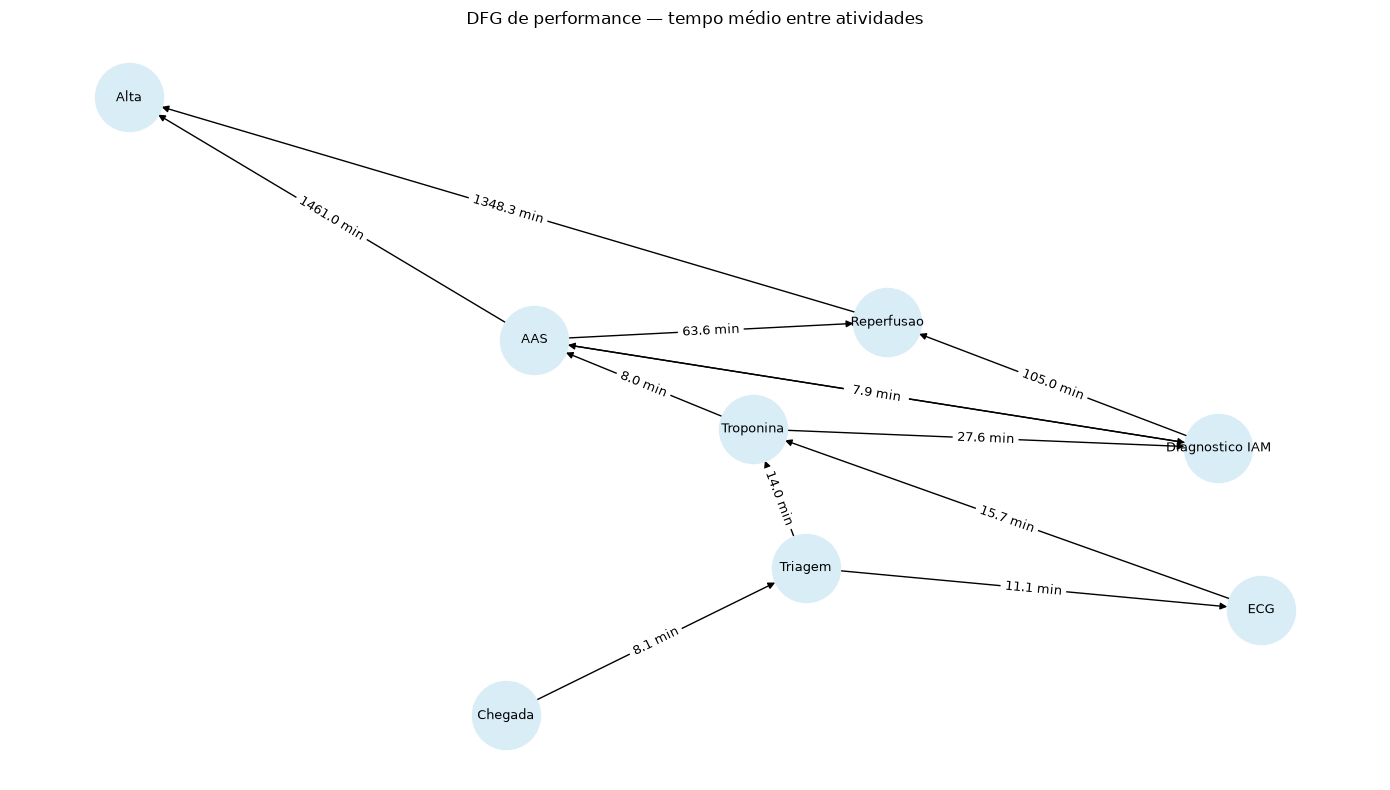

In [20]:
dfg_performance = dfg_discovery.apply(log, variant=dfg_discovery.Variants.PERFORMANCE)
grafo = nx.DiGraph()
for (origem, destino), tempo_segundos in dfg_performance.items():
    grafo.add_edge(origem, destino, tempo_minutos=tempo_segundos / 60)
posicoes = nx.spring_layout(grafo, seed=7)
plt.figure(figsize=(14, 8))
nx.draw_networkx(grafo, posicoes, node_color='#d9edf7', node_size=2400, arrows=True, font_size=9)
rotulos = {(origem, destino): f'{dados["tempo_minutos"]:.1f} min' for origem, destino, dados in grafo.edges(data=True)}
nx.draw_networkx_edge_labels(grafo, posicoes, edge_labels=rotulos, font_size=9)
plt.title('DFG de performance — tempo médio entre atividades')
plt.axis('off')
plt.tight_layout()
plt.show()


In [23]:
df.to_csv(ROOT / 'evidencias' / 'event_log_iam_enriched.csv', index=False)
case_summary.to_csv(ROOT / 'evidencias' / 'resumo_por_caso.csv', index=False)
activity_waits.to_csv(ROOT / 'evidencias' / 'tempos_por_atividade.csv', index=False)
conformidade_df.to_csv(ROOT / 'evidencias' / 'conformidade.csv', index=False)
pm4py.write_xes(log, str(ROOT / 'evidencias' / 'event_log_iam.xes'))
print('Arquivos analiticos exportados com sucesso.')


exporting log, completed traces ::   0%|          | 0/8 [00:00<?, ?it/s]

Arquivos analiticos exportados com sucesso.
